# CS 463 Project — Data Preparation (all stores)

Prepares the M5 Walmart data for forecasting in **all 10 stores across
California, Texas and Wisconsin**. A separate set of models is trained for
each state in `03_Modeling.ipynb`.

**Scenario:** a store manager orders stock once a week. On order day, they
need a forecast of each product's daily unit sales for the coming week, so
every sales-based feature uses only sales at least `HORIZON = 7` days old.

The processing code lives in `src/data_prep.py` (documented functions); this
notebook runs it and checks the results. For each store it:

1. Builds a products × days matrix of unit sales and of weekly prices.
2. Marks days before a product's first price as "not on sale yet".
3. Computes sales-history features on the matrix, shifted by 7 days.
4. Reshapes to one row per product per day and adds price, calendar, event
   and product features.
5. Removes Christmas (store closed) and pre-launch days, flags suspected
   stockouts, and drops rows without 98 days of history.
6. Splits by date into train / validation / test and saves Parquet files to
   `data/processed/<state>/`.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src import data_prep as dp

pd.set_option("display.max_columns", 80)

print("Horizon:", config.HORIZON, "days")
print("Train before:", config.TRAIN_END, "| test from:", config.TEST_START)
print("States and stores:", config.STATES)

Horizon: 7 days
Train before: 2014-10-08 | test from: 2015-07-17
States and stores: {'CA': ['CA_1', 'CA_2', 'CA_3', 'CA_4'], 'TX': ['TX_1', 'TX_2', 'TX_3'], 'WI': ['WI_1', 'WI_2', 'WI_3']}


## 1. Raw data

Three files from Kaggle's *M5 Forecasting – Accuracy* competition:

- `sales_train_validation.csv` — daily units sold for 30,490 product-store series (one column per day)
- `calendar.csv` — date, weekday, events and SNAP (food-assistance) days for each state
- `sell_prices.csv` — weekly price of each product in each store

In [2]:
start = time.time()
sales, calendar, prices = dp.load_raw()
print(f"Loaded in {time.time() - start:.0f}s")
print("Sales:", sales.shape, "| Calendar:", calendar.shape, "| Prices:", prices.shape)

day_cols = [c for c in sales.columns if c.startswith("d_")]
print("Sales days:", len(day_cols), f"({calendar['date'].iloc[0].date()} to {calendar['date'].iloc[len(day_cols) - 1].date()})")
sales.groupby(["state_id", "store_id"]).size().rename("products").to_frame().T

Loaded in 4s
Sales: (30490, 1919) | Calendar: (1969, 14) | Prices: (6841121, 4)
Sales days: 1913 (2011-01-29 to 2016-04-24)


state_id    CA                      TX                WI            
store_id  CA_1  CA_2  CA_3  CA_4  TX_1  TX_2  TX_3  WI_1  WI_2  WI_3
products  3049  3049  3049  3049  3049  3049  3049  3049  3049  3049

### Differences between states

Separate models per state are justified if the states behave differently.

In [3]:
daily_units = sales.groupby("state_id")[day_cols].sum().T
daily_units.index = calendar["date"].iloc[:len(day_cols)]

state_summary = pd.DataFrame({
    "stores": sales.groupby("state_id")["store_id"].nunique(),
    "avg units per product-day": sales.groupby("state_id")[day_cols].mean().mean(axis=1).round(2),
    "zero-sales days (%)": (sales.groupby("state_id")[day_cols].apply(lambda g: (g == 0).mean().mean()) * 100).round(1),
    "SNAP days": [calendar[f"snap_{s}"].sum() for s in sorted(config.STATES)],
})
state_summary

,stores,avg units per product-day,zero-sales days (%),SNAP days
state_id,,,,
CA,4,1.23,66.2,650
TX,3,1.08,69.1,650
WI,3,1.04,70.0,650


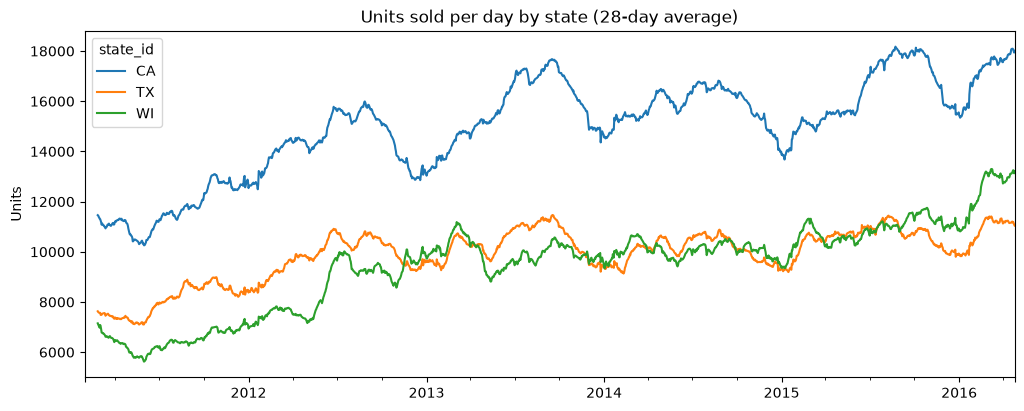

,non-SNAP day,SNAP day,SNAP lift (%)
CA,14606.0,15772.0,8.0
TX,9519.0,10613.0,12.0
WI,8839.0,10764.0,22.0


In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
daily_units.rolling(28).mean().plot(ax=ax)
ax.set_title("Units sold per day by state (28-day average)")
ax.set_xlabel("")
ax.set_ylabel("Units")
plt.show()

snap_effect = pd.DataFrame({
    state: daily_units[state].groupby(calendar[f"snap_{state}"].iloc[:len(day_cols)].to_numpy()).mean()
    for state in sorted(config.STATES)
}).T
snap_effect.columns = ["non-SNAP day", "SNAP day"]
snap_effect["SNAP lift (%)"] = ((snap_effect["SNAP day"] / snap_effect["non-SNAP day"] - 1) * 100).round(1)
snap_effect.round(0)

## 2. Features

All sales-history features end on order day (7 days before the target day).
One-hot groups drop their first level (Saturday, January, `FOODS_1`, the
first store), so no column is an exact sum of others — this avoids the
"dummy variable trap" that made plain linear regression unstable before.

| Group | Features | Idea |
|---|---|---|
| Recent sales | `sales_lag_7/14/21/28`, `rolling_mean_7/28/56/91`, `rolling_std_7/28` | Recent demand level and how much it varies |
| Last year | `sales_lag_364`, `has_last_year` | Same weekday a year earlier: seasonality and holidays |
| Demand shape | `zero_share_28/91`, `days_since_sale`, `trend_7_28`, `trend_28_91` | How intermittent the product is, and whether demand is rising or falling |
| Product | `product_age`, `dept_*` | New vs. established products; product department |
| Price | `sell_price`, `price_change`, `price_pct_change`, `price_discount`, `price_vs_usual`, `price_vs_department` | Price level, promotions (discount from the past year's highest price), and cheap vs. expensive within the department |
| Calendar | `wday_*`, `month_*`, `day_of_month`, `snap` | Weekly and yearly cycles, paycheck timing, SNAP days for the store's own state |
| Events | `event_type_*`, `days_until_event`, `days_since_event` | Holidays, and the build-up and wind-down around them |
| Store | `store_*` | Which store within the state |

In [5]:
for state in config.STATES:
    print(state, len(dp.feature_columns(state)), "features, store columns:", dp.store_features(state))

CA 58 features, store columns: ['store_CA_2', 'store_CA_3', 'store_CA_4']
TX 57 features, store columns: ['store_TX_2', 'store_TX_3']
WI 57 features, store columns: ['store_WI_2', 'store_WI_3']


## 3. Build every store

Each store takes a few seconds. Files are written to
`data/processed/<state>/<store>_<split>.parquet`.

In [6]:
summaries = []
start = time.time()

for state in config.STATES:
    summary = dp.prepare_state(state, sales, calendar, prices)
    summary.insert(0, "state", state)
    summaries.append(summary)
    print(f"{state} done ({time.time() - start:.0f}s)")

summary = pd.concat(summaries, ignore_index=True)
summary.to_csv(config.PROCESSED_DIR / "preparation_summary.csv", index=False)
summary

CA done (45s)


TX done (80s)


WI done (113s)


,state,store,product_days,removed_not_on_sale,removed_christmas,removed_short_history,rows_kept,suspected_stockouts,train_rows,validation_rows,test_rows
0,CA,CA_1,5832737,1129842,12642,295535,4394718,726135,2702718,834188,857812
1,CA,CA_2,5832737,1556961,11589,295428,3968759,665824,2371190,756390,841179
2,CA,CA_3,5832737,1160796,12575,295459,4363907,568892,2674099,832156,857652
3,CA,CA_4,5832737,1265551,12326,295469,4259391,684183,2579496,824647,855248
4,TX,TX_1,5832737,1120154,12702,295522,4404359,701577,2709423,836493,858443
5,TX,TX_2,5832737,1110228,12724,295529,4414256,716293,2720924,834928,858404
6,TX,TX_3,5832737,1180942,12550,295528,4343717,736542,2657911,828955,856851
7,WI,WI_1,5832737,1357342,12269,295179,4167947,646661,2475328,834514,858105
8,WI,WI_2,5832737,1271529,12358,295493,4253357,745031,2561004,834764,857589
9,WI,WI_3,5832737,1146068,12633,295523,4378513,753325,2688187,831584,858742


## 4. Data quality summary

- **Not on sale:** days before a product's first recorded price. All have
  zero sales; they mean "not on the shelf yet", not zero demand.
- **Christmas:** the stores are closed, so every product sells 0.
- **Short history:** the first 98 on-sale days of each product, which do not
  yet have a full 91-day window known on order day.
- **Suspected stockouts:** zero-sales runs with less than a 0.1% chance at the
  product's normal sales rate (Poisson). They stay in the files but are
  excluded from training.

In [7]:
quality = summary.groupby("state")[[
    "product_days", "removed_not_on_sale", "removed_christmas",
    "removed_short_history", "rows_kept", "suspected_stockouts",
    "train_rows", "validation_rows", "test_rows",
]].sum()
quality["stockout share (%)"] = (quality["suspected_stockouts"] / quality["rows_kept"] * 100).round(1)
quality.loc["All"] = quality.sum(numeric_only=True)
quality.loc["All", "stockout share (%)"] = round(quality.loc["All", "suspected_stockouts"] / quality.loc["All", "rows_kept"] * 100, 1)
quality.T

state,CA,TX,WI,All
product_days,23330948.0,17498211.0,17498211.0,58327370.0
removed_not_on_sale,5113150.0,3411324.0,3774939.0,12299413.0
removed_christmas,49132.0,37976.0,37260.0,124368.0
removed_short_history,1181891.0,886579.0,886195.0,2954665.0
rows_kept,16986775.0,13162332.0,12799817.0,42948924.0
suspected_stockouts,2645034.0,2154412.0,2145017.0,6944463.0
train_rows,10327503.0,8088258.0,7724519.0,26140280.0
validation_rows,3247381.0,2500376.0,2500862.0,8248619.0
test_rows,3411891.0,2573698.0,2574436.0,8560025.0
stockout share (%),15.6,16.4,16.8,16.2


## 5. Checks

The checks below reload one state's training data and confirm that:

- no feature has missing values;
- the target and the history features match the raw sales exactly, which
  proves no feature uses sales from after order day.

In [8]:
check_state = "TX"
features = dp.load_features(check_state)
train = dp.load_split(check_state, "train")
print(check_state, "training rows:", f"{len(train):,}", "| features:", len(features))
print("Missing feature values:", int(train[features].isna().sum().sum()))

raw = sales[sales["state_id"] == check_state].set_index(["store_id", "item_id"])
raw_matrix = raw[day_cols].to_numpy(float)
day_index = pd.Series(np.arange(len(calendar)), index=calendar["date"])

sample = train.sample(50_000, random_state=config.SEED)
rows = raw.index.get_indexer(pd.MultiIndex.from_arrays([sample["store_id"].astype(str), sample["item_id"].astype(str)]))
days = sample["date"].map(day_index).to_numpy()

window_28 = np.stack([raw_matrix[rows, days - 7 - k] for k in range(28)], axis=1)
has_ly = sample["has_last_year"].to_numpy() == 1

checks = {
    "target = raw sales on the target day": np.allclose(raw_matrix[rows, days], sample["target_sales"]),
    "sales_lag_7 = raw sales 7 days earlier": np.allclose(raw_matrix[rows, days - 7], sample["sales_lag_7"]),
    "rolling_mean_28 = mean of days t-34 .. t-7": np.allclose(window_28.mean(axis=1), sample["rolling_mean_28"], atol=1e-4),
    "sales_lag_364 = raw sales 364 days earlier": np.allclose(raw_matrix[rows[has_ly], days[has_ly] - 364], sample["sales_lag_364"][has_ly]),
}
pd.Series(checks, name="passed").to_frame()

TX training rows: 8,088,258 | features: 57


Missing feature values: 0


,passed
target = raw sales on the target day,True
sales_lag_7 = raw sales 7 days earlier,True
rolling_mean_28 = mean of days t-34 .. t-7,True
sales_lag_364 = raw sales 364 days earlier,True


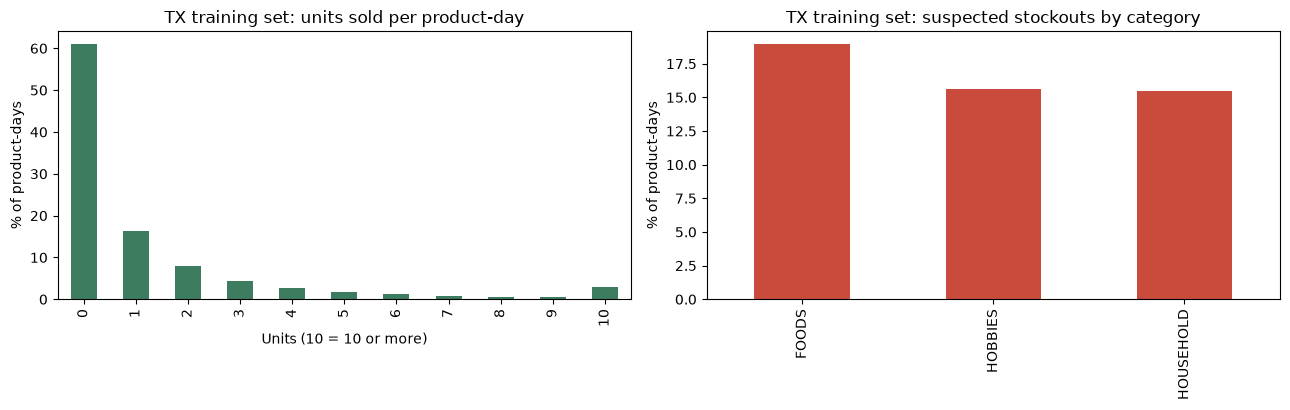

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

units = train["target_sales"].clip(upper=10)
(units.value_counts(normalize=True).sort_index() * 100).plot(kind="bar", ax=axes[0], color="#3E7C5F")
axes[0].set_title(f"{check_state} training set: units sold per product-day")
axes[0].set_xlabel("Units (10 = 10 or more)")
axes[0].set_ylabel("% of product-days")

train.groupby("cat_id", observed=True)["is_suspected_stockout"].mean().mul(100).plot(kind="bar", ax=axes[1], color="#C84B3C")
axes[1].set_title(f"{check_state} training set: suspected stockouts by category")
axes[1].set_xlabel("")
axes[1].set_ylabel("% of product-days")

plt.tight_layout()
plt.show()